## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [34]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?
* The data is right skewed, most tokens appear a few times, with a small amount appearing frequently. It looks like a very tall bar on the low side of occurences per token and a tail going to the right.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
* The $R^2$ on the training set rounded to 4 decimal places is: .7675. On the test set it is: -1.3066351978252998e+21
3. What words have the largest coefficients in absolute value and most strongly influence predictions?
* 2001      |   -9.483527e+12
* 1999      |    8.437759e+12
* cnn,      |   -8.212047e+12
* 16,       |   -7.619397e+12
* 23,       |   -7.302139e+12
* 1000      |   7.245405e+12
* 2000      |   -7.170863e+12
* wysak     |    6.942836e+12
* wysk      |  -6.942836e+12
* revamping |   6.920537e+12

* These are the words that have the largest coefficients in absolute value and thus strong influence the predictions more given the current fit.

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?
* There are some slight patterns that I noticed. Despite not being completely separated the phishing emails appear to be higher with the PC2 values with the non phishing emails appearing at lower PC2 values but with higher PC1 values/further to the right of the plot.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?
* PCA Train R^2: 0.766896761127783
* PCA Test R^2: 0.6613559301353326
* Q2 Training R^2: 0.7674941582634685
* Q2 Test R^2: -1.3066351978252998e+21

* The performance of the PCA regression is much better as we no longer have a large negative R^2 for the test set, which means our predictions are better. 

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

* This advantage of using the principal components to run this regression, instead of the original data is that it allows us to have better predictions, which from doing the principal components allowed us to remove some of the lowest variations that caused the instability of predcitions previously, which had that large negative value. PCA itself combines the features into new variables while preserving most of the variation

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jalen Medley

**Date:** 10/21/2026

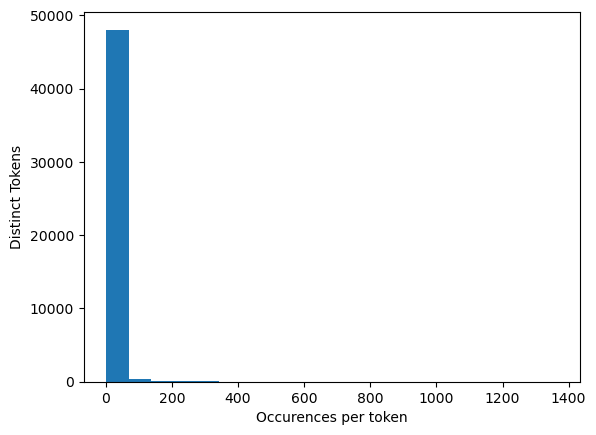

In [35]:
# Your Phase 1 solution to the problem goes here.
import matplotlib.pyplot as plt

words = [word for word, count in token_freq]
frequencies = [count for word, count in  token_freq]

plt.hist(frequencies, bins=20)
plt.xlabel("Occurences per token")
plt.ylabel("Distinct Tokens")
plt.show()


In [36]:
import pandas as pd

df = pd.read_parquet("data/Phishing_clean.parquet")


In [37]:
from sklearn.model_selection import train_test_split

eval_x = df.drop(columns="Email Type")
eval_y = df["Email Type"]

eval_x_train, eval_x_valid, eval_y_train, eval_y_valid = train_test_split(eval_x, eval_y, test_size=.2, random_state=65)

In [38]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(eval_x_train, eval_y_train)

train_r2 = round(model.score(eval_x_train, eval_y_train), 4)
test_r2 = round(model.score(eval_x_valid, eval_y_valid) , 4)

print("Training R^2:", train_r2)
print("Test R^2:", test_r2)

Training R^2: 0.7675
Test R^2: -1.3066351978252998e+21


In [39]:
coef = pd.Series(model.coef_, index=eval_x_train.columns)

influence = coef.reindex(coef.abs().sort_values(ascending=False).index)

print(influence.head(10))

2001        -9.483527e+12
1999         8.437759e+12
cnn,        -8.212047e+12
16,         -7.619397e+12
23,         -7.302139e+12
1000         7.245405e+12
2000        -7.170863e+12
wysak        6.942836e+12
wysk        -6.942836e+12
revamping    6.920537e+12
dtype: float64


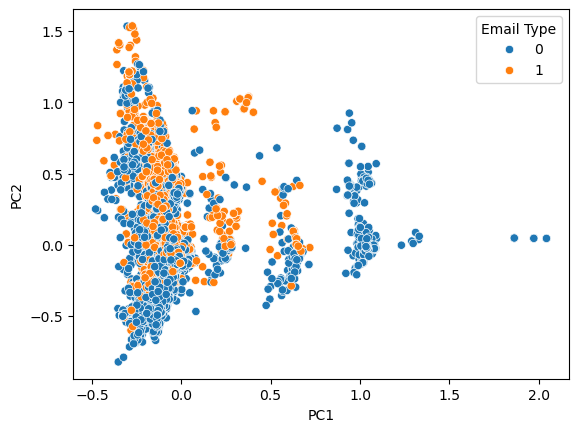

In [40]:
from sklearn.decomposition import PCA
import seaborn as sns

pca_x = df.drop(columns="Email Type")
pca_y = df["Email Type"]

pca = PCA(n_components=2).fit(pca_x)
X_pca_sklearn = pca.transform(pca_x)

phising_df = pd.DataFrame(X_pca_sklearn, columns=["PC1", "PC2"])
phising_df["Email Type"] = pca_y.to_numpy()

sns.scatterplot(data=phising_df, x="PC1", y="PC2", hue="Email Type")
plt.show()

In [41]:
pca_large = PCA(n_components=2610)
x_train_pca = pca_large.fit(eval_x_train)
x_train_pca = x_train_pca.transform(eval_x_train)

x_test_pca = pca_large.transform(eval_x_valid)

pca_model = LinearRegression()
pca_model.fit(x_train_pca, eval_y_train)

print("PCA Train R^2:", pca_model.score(x_train_pca, eval_y_train))
print("PCA Test R^2:", pca_model.score(x_test_pca, eval_y_valid))

print("Q2 Training R^2:", model.score(eval_x_train, eval_y_train))
print("Q2 Test R^2:", model.score(eval_x_valid, eval_y_valid))

PCA Train R^2: 0.766896761127783
PCA Test R^2: 0.6613559301353326
Q2 Training R^2: 0.7674941582634685
Q2 Test R^2: -1.3066351978252998e+21


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 8846331ea744c9c191a28648e95f6b7f5a00d5d6
- **AI tool and model used:** GPT-6 Astra

### *Prompts used

1. Given the code, questions, and my answers. Provide me with a concise numbered list of changes needed to ensure my answers are right.

### *AI-proposed changes


1. Q5: Explain that keeping the first 2,610 components removes the 101 lowest-variance directions and can reduce regression instability. Say this improved test predictions in your results, rather than implying PCA always improves predictions or that you proved exactly what caused the original instability.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I am accepting this because it is essentially building off of what I already had said, just making it more direct and the meaning behind what I was saying more clear. This matches up with what we have learned about PCA in general |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?
* The data is right skewed, most tokens appear a few times, with a small amount appearing frequently. It looks like a very tall bar on the low side of occurences per token and a tail going to the right.

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
* The $R^2$ on the training set rounded to 4 decimal places is: .7675. On the test set it is: -1.3066351978252998e+21
3. What words have the largest coefficients in absolute value and most strongly influence predictions?
* 2001      |   -9.483527e+12
* 1999      |    8.437759e+12
* cnn,      |   -8.212047e+12
* 16,       |   -7.619397e+12
* 23,       |   -7.302139e+12
* 1000      |   7.245405e+12
* 2000      |   -7.170863e+12
* wysak     |    6.942836e+12
* wysk      |  -6.942836e+12
* revamping |   6.920537e+12

* These are the words that have the largest coefficients in absolute value and thus strong influence the predictions more given the current fit.

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?
* There are some slight patterns that I noticed. Despite not being completely separated the phishing emails appear to be higher with the PC2 values with the non phishing emails appearing at lower PC2 values but with higher PC1 values/further to the right of the plot.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?
* PCA Train R^2: 0.766896761127783
* PCA Test R^2: 0.6613559301353326
* Q2 Training R^2: 0.7674941582634685
* Q2 Test R^2: -1.3066351978252998e+21

* The performance of the PCA regression is much better as we no longer have a large negative R^2 for the test set, which means our predictions are better. 

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

* This advantage of using the principal components to run this regression, instead of the original data is that it allows us to have better predictions, which from doing the principal components allowed us to remove 101 of the lowest-variance directions which can reduce our regression instability. This thus improved the the test predictions in my results. PCA itself combines the features into new variables while preserving most of the variation

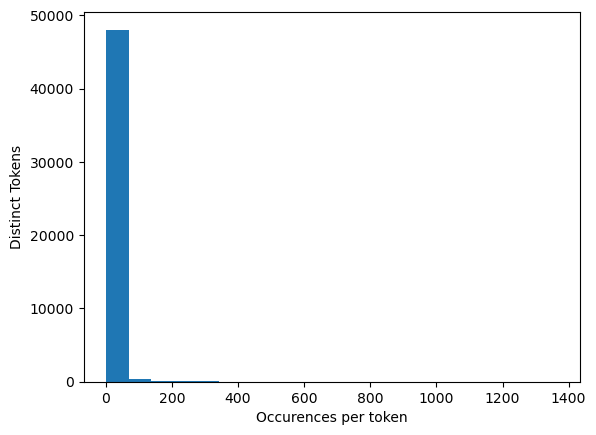

In [42]:
# Your Phase 1 solution to the problem goes here.
import matplotlib.pyplot as plt

words = [word for word, count in token_freq]
frequencies = [count for word, count in  token_freq]

plt.hist(frequencies, bins=20)
plt.xlabel("Occurences per token")
plt.ylabel("Distinct Tokens")
plt.show()


In [43]:
import pandas as pd

df = pd.read_parquet("data/Phishing_clean.parquet")


In [44]:
from sklearn.model_selection import train_test_split

eval_x = df.drop(columns="Email Type")
eval_y = df["Email Type"]

eval_x_train, eval_x_valid, eval_y_train, eval_y_valid = train_test_split(eval_x, eval_y, test_size=.2, random_state=65)

In [45]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(eval_x_train, eval_y_train)

train_r2 = round(model.score(eval_x_train, eval_y_train), 4)
test_r2 = round(model.score(eval_x_valid, eval_y_valid) , 4)

print("Training R^2:", train_r2)
print("Test R^2:", test_r2)

Training R^2: 0.7675
Test R^2: -1.3066351978252998e+21


In [46]:
coef = pd.Series(model.coef_, index=eval_x_train.columns)

influence = coef.reindex(coef.abs().sort_values(ascending=False).index)

print(influence.head(10))

2001        -9.483527e+12
1999         8.437759e+12
cnn,        -8.212047e+12
16,         -7.619397e+12
23,         -7.302139e+12
1000         7.245405e+12
2000        -7.170863e+12
wysak        6.942836e+12
wysk        -6.942836e+12
revamping    6.920537e+12
dtype: float64


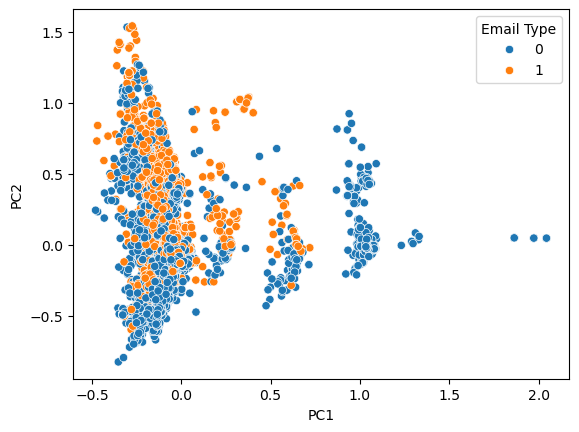

In [47]:
from sklearn.decomposition import PCA
import seaborn as sns

pca_x = df.drop(columns="Email Type")
pca_y = df["Email Type"]

pca = PCA(n_components=2).fit(pca_x)
X_pca_sklearn = pca.transform(pca_x)

phising_df = pd.DataFrame(X_pca_sklearn, columns=["PC1", "PC2"])
phising_df["Email Type"] = pca_y.to_numpy()

sns.scatterplot(data=phising_df, x="PC1", y="PC2", hue="Email Type")
plt.show()

In [48]:
pca_large = PCA(n_components=2610)
x_train_pca = pca_large.fit(eval_x_train)
x_train_pca = x_train_pca.transform(eval_x_train)

x_test_pca = pca_large.transform(eval_x_valid)

pca_model = LinearRegression()
pca_model.fit(x_train_pca, eval_y_train)

print("PCA Train R^2:", pca_model.score(x_train_pca, eval_y_train))
print("PCA Test R^2:", pca_model.score(x_test_pca, eval_y_valid))

print("Q2 Training R^2:", model.score(eval_x_train, eval_y_train))
print("Q2 Test R^2:", model.score(eval_x_valid, eval_y_valid))

PCA Train R^2: 0.766896761127783
PCA Test R^2: 0.6613559301353326
Q2 Training R^2: 0.7674941582634685
Q2 Test R^2: -1.3066351978252998e+21


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements the AI had in my phase, a sper usual, is making sure that my answers to the questions are concrete, accurate, and make sense in trying to get my point across. They didn't find any issues with my code during this phase. So the AI was able to improve my question clarity and ensure that it can properly get my point across to the grader. In this case there were no mistakes or limitations with the AI as it only suggested one small change in wording to question 5. The final solution was verified by cross referencing with the class materials, but also in further understanding the point I was trying to get across and how I can communicate that to the graders. I don't have any remaining concerns with the AI and am glad that for the most part it appears my answers/code were written correctly.